<a href="https://colab.research.google.com/github/astromohamedemara-26/RADMC3D-Interstellar-Dust-Simulation/blob/main/RADMC3D_Dust_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!apt-get -qq update
!apt-get -qq install -y gfortran make git
!git clone -q https://github.com/dullemond/radmc3d-2.0.git
!cd radmc3d-2.0/src && make -s
!radmc3d-2.0/src/radmc3d

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  
      WELCOME TO RADMC-3D: A 3-D CONTINUUM AND LINE RT SOLVER    
                                                                 
                          VERSION 2.0                            
                                                                 
                (c) 2008-2023 Cornelis Dullemond                 
                                                                 
       Please feel free to ask questions. Also please report     
        bugs and/or suspicious behavior without hestitation.     
      The reliability of this code depends on your vigilance!    
                    dullemond@uni-heidelberg.de                  
                                                                 
   To keep up-to-date with bug-alarms and bugfixes, follow the   
                

In [2]:
import os

project = "/content/dust_cloud"
os.makedirs(project, exist_ok=True)
os.chdir(project)

print("Project created successfully!")
print("Working directory:", os.getcwd())

Project created successfully!
Working directory: /content/dust_cloud


3D density grid: (64, 64, 64)
Maximum density: 9.966044175295977e-19


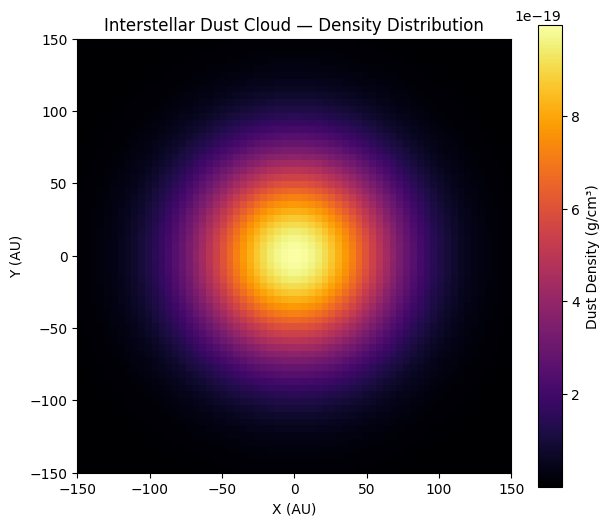

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
AU = 1.496e13  # cm

# Cloud parameters
rho0 = 1e-18       # g/cm^3 (dust density)
sigma = 50 * AU    # Cloud width

# 3D Cartesian grid
n = 64
x = np.linspace(-150*AU, 150*AU, n)
y = np.linspace(-150*AU, 150*AU, n)
z = np.linspace(-150*AU, 150*AU, n)

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

# Distance from the center
R = np.sqrt(X**2 + Y**2 + Z**2)

# Gaussian density distribution
rho = rho0 * np.exp(-R**2 / (2*sigma**2))

print("3D density grid:", rho.shape)
print("Maximum density:", rho.max())

# Visualize the central slice
plt.figure(figsize=(7, 6))
plt.imshow(
    rho[:, :, n//2],
    origin="lower",
    extent=[-150, 150, -150, 150],
    cmap="inferno"
)
plt.colorbar(label="Dust Density (g/cm³)")
plt.xlabel("X (AU)")
plt.ylabel("Y (AU)")
plt.title("Interstellar Dust Cloud — Density Distribution")
plt.show()

In [5]:
import numpy as np
import os

os.chdir("/content/dust_cloud")

# Grid cell boundaries
AU = 1.496e13
n = 64

edges = np.linspace(-150*AU, 150*AU, n+1)

# Cell centers
centers = 0.5 * (edges[:-1] + edges[1:])

X, Y, Z = np.meshgrid(
    centers, centers, centers, indexing="ij"
)

R = np.sqrt(X**2 + Y**2 + Z**2)

# Dust density
rho0 = 1e-18
sigma = 50 * AU

rho = rho0 * np.exp(-R**2 / (2*sigma**2))

# Write Cartesian grid
with open("amr_grid.inp", "w") as f:
    f.write("1\n")        # Format number
    f.write("0\n")        # Regular grid
    f.write("0\n")        # Cartesian coordinates
    f.write("0\n")        # Grid information
    f.write("1 1 1\n")    # Active dimensions
    f.write(f"{n} {n} {n}\n")

    for axis in [edges, edges, edges]:
        for value in axis:
            f.write(f"{value:.9e}\n")

# Write dust density
with open("dust_density.inp", "w") as f:
    f.write("1\n")
    f.write(f"{n**3}\n")
    f.write("1\n")        # One dust species

    # Fortran ordering: x varies fastest
    for value in rho.flatten(order="F"):
        f.write(f"{value:.9e}\n")

print("RADMC-3D input files created successfully!")
print("Number of cells:", n**3)
print("Files:", os.listdir())


RADMC-3D input files created successfully!
Number of cells: 262144
Files: ['dust_density.inp', 'amr_grid.inp']


In [6]:
import numpy as np
import os

os.chdir("/content/dust_cloud")

# Grid cell boundaries
AU = 1.496e13
n = 64

edges = np.linspace(-150*AU, 150*AU, n+1)

# Cell centers
centers = 0.5 * (edges[:-1] + edges[1:])

X, Y, Z = np.meshgrid(
    centers, centers, centers, indexing="ij"
)

R = np.sqrt(X**2 + Y**2 + Z**2)

# Dust density
rho0 = 1e-18
sigma = 50 * AU

rho = rho0 * np.exp(-R**2 / (2*sigma**2))

# Write Cartesian grid
with open("amr_grid.inp", "w") as f:
    f.write("1\n")        # Format number
    f.write("0\n")        # Regular grid
    f.write("0\n")        # Cartesian coordinates
    f.write("0\n")        # Grid information
    f.write("1 1 1\n")    # Active dimensions
    f.write(f"{n} {n} {n}\n")

    for axis in [edges, edges, edges]:
        for value in axis:
            f.write(f"{value:.9e}\n")

# Write dust density
with open("dust_density.inp", "w") as f:
    f.write("1\n")
    f.write(f"{n**3}\n")
    f.write("1\n")        # One dust species

    # Fortran ordering: x varies fastest
    for value in rho.flatten(order="F"):
        f.write(f"{value:.9e}\n")

print("RADMC-3D input files created successfully!")
print("Number of cells:", n**3)
print("Files:", os.listdir())

RADMC-3D input files created successfully!
Number of cells: 262144
Files: ['dust_density.inp', 'amr_grid.inp']


In [7]:
import os

os.chdir("/content/dust_cloud")

required_files = [
    "amr_grid.inp",
    "dust_density.inp",
    "wavelength_micron.inp",
    "stars.inp",
    "dustopac.inp",
    "dustkappa_silicate.inp",
    "radmc3d.inp"
]

for file in required_files:
    status = "OK" if os.path.exists(file) else "MISSING"
    print(f"{file}: {status}")

amr_grid.inp: OK
dust_density.inp: OK
wavelength_micron.inp: MISSING
stars.inp: MISSING
dustopac.inp: MISSING
dustkappa_silicate.inp: MISSING
radmc3d.inp: MISSING


In [8]:
import numpy as np
import os

os.chdir("/content/dust_cloud")

# Wavelength grid (microns)
lam = np.logspace(-1, 4, 150)

np.savetxt(
    "wavelength_micron.inp",
    lam,
    header=str(len(lam)),
    comments=""
)

# Star parameters (CGS)
Rsun = 6.957e10
Msun = 1.989e33

with open("stars.inp", "w") as f:
    f.write("2\n")
    f.write(f"1 {len(lam)}\n")
    f.write(f"{Rsun} {Msun} 0 0 0\n")

    for l in lam:
        f.write(f"{l}\n")

    f.write("-5772\n")

# Simplified dust opacity
kappa = 10.0 / lam

with open("dustkappa_silicate.inp", "w") as f:
    f.write("2\n")
    f.write(f"{len(lam)}\n")

    for l, k in zip(lam, kappa):
        f.write(f"{l} {k}\n")

# Dust opacity configuration
with open("dustopac.inp", "w") as f:
    f.write("2\n")
    f.write("1\n")
    f.write("============================================================================\n")
    f.write("1\n")
    f.write("0\n")
    f.write("silicate\n")
    f.write("----------------------------------------------------------------------------\n")

# RADMC-3D settings
with open("radmc3d.inp", "w") as f:
    f.write("nphot = 100000\n")
    f.write("scattering_mode_max = 0\n")

print("STEP 5 COMPLETED!")

for file in [
    "wavelength_micron.inp",
    "stars.inp",
    "dustopac.inp",
    "dustkappa_silicate.inp",
    "radmc3d.inp"
]:
    print(file, os.path.exists(file))

STEP 5 COMPLETED!
wavelength_micron.inp True
stars.inp True
dustopac.inp True
dustkappa_silicate.inp True
radmc3d.inp True


In [9]:
import numpy as np
import os
import subprocess

os.chdir("/content/dust_cloud")

AU = 1.496e13
n = 64

# Rebuild the grid header with Cartesian coordinates
edges = np.linspace(-150*AU, 150*AU, n+1)
centers = (edges[:-1] + edges[1:]) / 2

with open("amr_grid.inp", "w") as f:
    f.write("1\n0\n0\n0\n1 1 1\n")
    f.write(f"{n} {n} {n}\n")
    for axis in (edges, edges, edges):
        for value in axis:
            f.write(f"{value:.9e}\n")

# Recalculate density with an inner cavity
X, Y, Z = np.meshgrid(
    centers, centers, centers, indexing="ij"
)

R = np.sqrt(X**2 + Y**2 + Z**2)

rho0 = 1e-18
sigma = 50 * AU

rho = rho0 * np.exp(-R**2 / (2*sigma**2))

# Remove dust within 5 AU
rho[R < 5*AU] = 0.0

with open("dust_density.inp", "w") as f:
    f.write(f"1\n{n**3}\n1\n")
    np.savetxt(f, rho.flatten(order="F"), fmt="%.9e")

# Locate RADMC-3D executable
radmc = "/content/radmc3d-2.0/src/radmc3d"

# Run thermal Monte Carlo simulation
result = subprocess.run(
    [radmc, "mctherm"],
    capture_output=True,
    text=True
)

print(result.stdout[-3000:])
print(result.stderr[-1000:])
print("Return code:", result.returncode)
print(
    "Temperature file created:",
    os.path.exists("dust_temperature.dat")
)

  
      WELCOME TO RADMC-3D: A 3-D CONTINUUM AND LINE RT SOLVER    
                                                                 
                          VERSION 2.0                            
                                                                 
                (c) 2008-2023 Cornelis Dullemond                 
                                                                 
       Please feel free to ask questions. Also please report     
        bugs and/or suspicious behavior without hestitation.     
      The reliability of this code depends on your vigilance!    
                    dullemond@uni-heidelberg.de                  
                                                                 
   To keep up-to-date with bug-alarms and bugfixes, follow the   
                     RADMC-3D code on github                     
             https://github.com/dullemond/radmc3d-2.0            
                                                                 
       

In [10]:
import numpy as np
import os
import subprocess

os.chdir("/content/dust_cloud")

# Fix dust opacity file
lam = np.logspace(-1, 4, 150)
kappa = 10.0 / lam

with open("dustkappa_silicate.inp", "w") as f:
    f.write("1\n")  # Format 1: absorption only
    f.write(f"{len(lam)}\n")

    for l, k in zip(lam, kappa):
        f.write(f"{l:.9e} {k:.9e}\n")

print("Dust opacity file corrected!")

# Run RADMC-3D again
radmc = "/content/radmc3d-2.0/src/radmc3d"

result = subprocess.run(
    [radmc, "mctherm"],
    capture_output=True,
    text=True
)

print(result.stdout[-2000:])
print(result.stderr[-1000:])

print("Return code:", result.returncode)
print(
    "Temperature file created:",
    os.path.exists("dust_temperature.dat")
)

Dust opacity file corrected!
0
 Thread:           0 Photon nr:                72000
 Thread:           0 Photon nr:                73000
 Thread:           0 Photon nr:                74000
 Thread:           0 Photon nr:                75000
 Thread:           0 Photon nr:                76000
 Thread:           0 Photon nr:                77000
 Thread:           0 Photon nr:                78000
 Thread:           0 Photon nr:                79000
 Thread:           0 Photon nr:                80000
 Thread:           0 Photon nr:                81000
 Thread:           0 Photon nr:                82000
 Thread:           0 Photon nr:                83000
 Thread:           0 Photon nr:                84000
 Thread:           0 Photon nr:                85000
 Thread:           0 Photon nr:                86000
 Thread:           0 Photon nr:                87000
 Thread:           0 Photon nr:                88000
 Thread:           0 Photon nr:                89000
 Thread:       

Format: 1
Number of cells: 262144
Dust species: 1
Minimum dust temperature: 0.0 K
Maximum dust temperature: 226.97127797141871 K


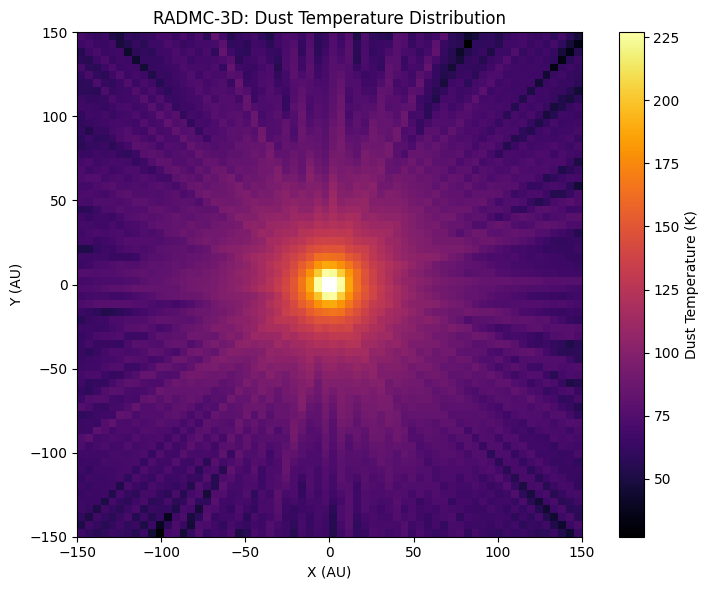

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.chdir("/content/dust_cloud")

n = 64
AU = 1.496e13

# Read RADMC-3D temperature output
with open("dust_temperature.dat", "r") as f:
    format_number = int(f.readline())
    ncells = int(f.readline())
    nspecies = int(f.readline())
    temperature = np.loadtxt(f)

print("Format:", format_number)
print("Number of cells:", ncells)
print("Dust species:", nspecies)

assert ncells == n**3
assert nspecies == 1

# Restore the 3D grid
T = temperature.reshape((n, n, n), order="F")

# Dust density from the previous step
mask = rho > 0

print("Minimum dust temperature:", T[mask].min(), "K")
print("Maximum dust temperature:", T[mask].max(), "K")

# Central XY slice
T_slice = T[:, :, n//2].copy()
density_slice = rho[:, :, n//2]

# Hide cells without dust
T_slice[density_slice <= 0] = np.nan

plt.figure(figsize=(8, 6))

plt.imshow(
    T_slice.T,
    origin="lower",
    extent=[-150, 150, -150, 150],
    cmap="inferno"
)

plt.colorbar(label="Dust Temperature (K)")
plt.xlabel("X (AU)")
plt.ylabel("Y (AU)")
plt.title("RADMC-3D: Dust Temperature Distribution")

plt.tight_layout()
plt.show()

In [12]:
import os
import subprocess
import numpy as np

os.chdir("/content/dust_cloud")

# Save original temperature
T_old = T.copy()

# Increase photon packets
with open("radmc3d.inp", "w") as f:
    f.write("nphot = 1000000\n")
    f.write("scattering_mode_max = 0\n")

radmc = "/content/radmc3d-2.0/src/radmc3d"

result = subprocess.run(
    [radmc, "mctherm"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-500:])
print(result.stderr[-500:])

if result.returncode == 0:
    with open("dust_temperature.dat") as f:
        fmt = int(f.readline())
        ncells = int(f.readline())
        nspecies = int(f.readline())
        values = np.loadtxt(f)

    T_new = values.reshape((64, 64, 64), order="F")

    dust_mask = rho > 0

    print("Old zero-temperature dust cells:",
          np.sum((T_old == 0) & dust_mask))

    print("New zero-temperature dust cells:",
          np.sum((T_new == 0) & dust_mask))

    print("New maximum temperature:",
          T_new[dust_mask].max(), "K")

Return code: 0
     0 Photon nr:              1000000
 Elapsed time:   11.005302146999838     
 Done with Bjorkman & Wood Monte Carlo simulation
 Using the parallel version of RADMC-3D
 Number of parallel threads used:            1
 Average number of abs/scat events per photon package =    1.2925000000000001E-002
 Average nr of times a photon stays in the same cell  =    0.0000000000000000     
 Maximum nr of times a photon stayed in the same cell =            0
 Saving results of thermal Monte Carlo
 Done...


Old zero-temperature dust cells: 51
New zero-temperature dust cells: 0
New maximum temperature: 226.4596673680049 K


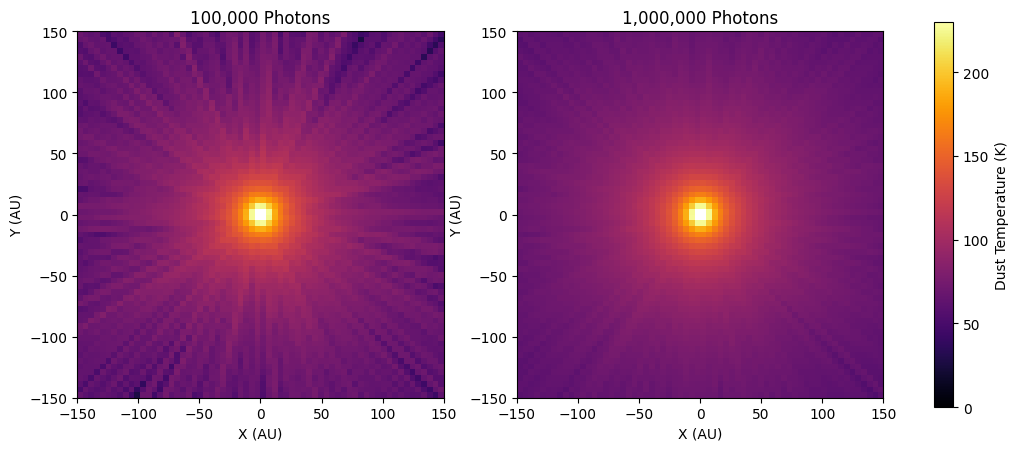

In [17]:
import numpy as np
import matplotlib.pyplot as plt

n = 64
mid = n // 2

# Central slices
old_slice = T_old[:, :, mid].T.copy()
new_slice = T_new[:, :, mid].T.copy()

# Mask empty dust cells
dust_slice = rho[:, :, mid].T > 0

old_slice[~dust_slice] = np.nan
new_slice[~dust_slice] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, title in zip(
    axes,
    [old_slice, new_slice],
    ["100,000 Photons", "1,000,000 Photons"]
):
    im = ax.imshow(
        data,
        origin="lower",
        extent=[-150, 150, -150, 150],
        cmap="inferno",
        vmin=0,
        vmax=230
    )

    ax.set_title(title)
    ax.set_xlabel("X (AU)")
    ax.set_ylabel("Y (AU)")

fig.colorbar(im, ax=axes, label="Dust Temperature (K)")
plt.show()

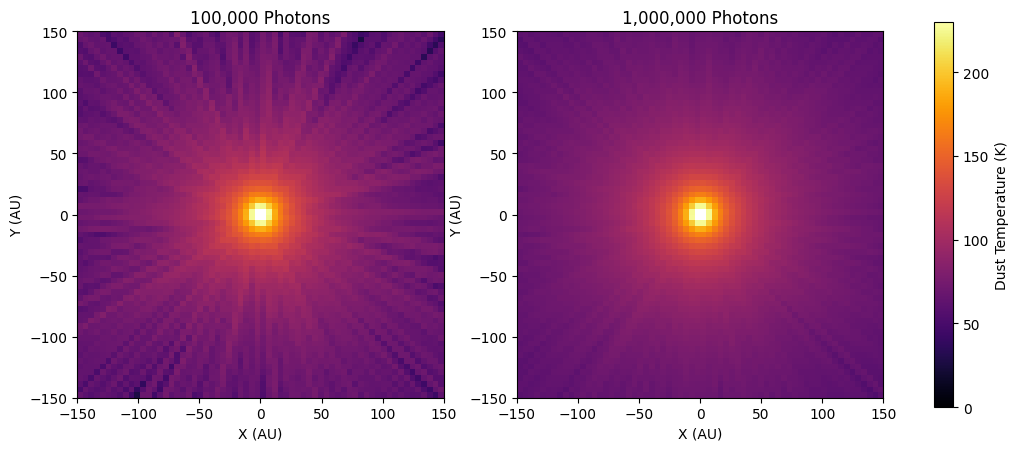

In [18]:
import numpy as np
import matplotlib.pyplot as plt

n = 64
mid = n // 2

# Central slices
old_slice = T_old[:, :, mid].T.copy()
new_slice = T_new[:, :, mid].T.copy()

# Mask empty dust cells
dust_slice = rho[:, :, mid].T > 0

old_slice[~dust_slice] = np.nan
new_slice[~dust_slice] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, title in zip(
    axes,
    [old_slice, new_slice],
    ["100,000 Photons", "1,000,000 Photons"]
):
    im = ax.imshow(
        data,
        origin="lower",
        extent=[-150, 150, -150, 150],
        cmap="inferno",
        vmin=0,
        vmax=230
    )

    ax.set_title(title)
    ax.set_xlabel("X (AU)")
    ax.set_ylabel("Y (AU)")

fig.colorbar(im, ax=axes, label="Dust Temperature (K)")
plt.show()

Return code: 0
                   
              Please visit the RADMC-3D home page at             
  http://www.ita.uni-heidelberg.de/~dullemond/software/radmc-3d/ 
  
 Number of processors:            2
 Number of threads in use:            1
 Reading global frequencies/wavelengths...
 Reading grid file and prepare grid tree...
 Reading star data...
 Note: Star 1 is taken to be a blackbody star
       at a temperature T = 5772. Kelvin
 Grid information (current status):
   We have 262144 branches, of which 262144 are actual grid cells.
   ---> 100.000% mem use for branches, and 100.000% mem use for actual cells.
   No grid refinement is active. The AMR tree is not allocated (this saves memory).
 Reading the heat source spatial distribution...
 Starting procedure for rendering image...
   --> Including dust
       No lines included...
       No gas continuum included...
 Reading dust data...
 Reading dust densities...
 Dust mass total =    3.2841975042622872E-006  Msun
 Reading dust 

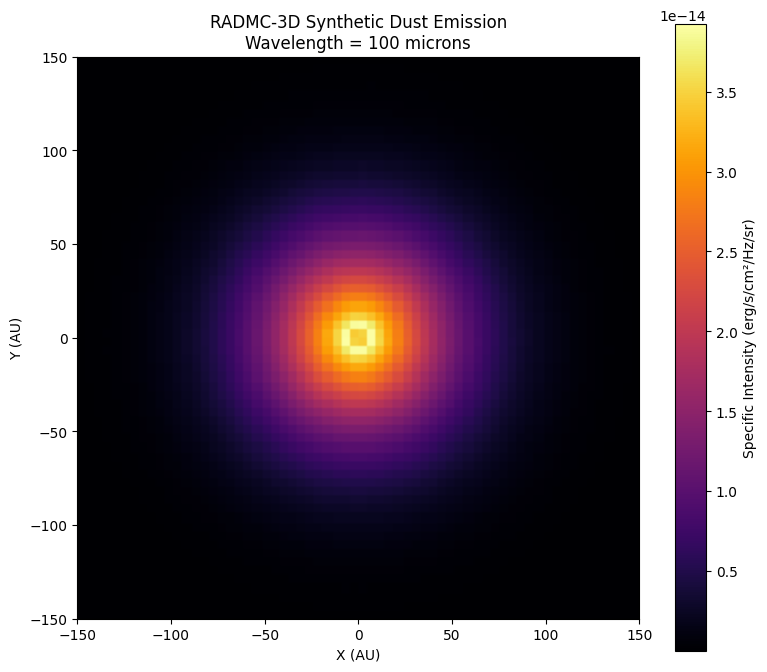

Synthetic image generated successfully!


In [19]:
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# STEP 10: RADMC-3D SYNTHETIC IMAGE
# =====================================

# Project directory
os.chdir("/content/dust_cloud")

# RADMC-3D executable
radmc = "/content/radmc3d-2.0/src/radmc3d"

# Remove any previous image
if os.path.exists("image.out"):
    os.remove("image.out")

# =====================================
# 1. GENERATE SYNTHETIC IMAGE
# =====================================

result = subprocess.run(
    [
        radmc,
        "image",
        "lambda", "100",
        "npix", "200",
        "sizeau", "300",
        "incl", "0",
        "phi", "0",
        "nostar"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-1500:])
print(result.stderr[-1000:])

# =====================================
# 2. READ RADMC-3D IMAGE
# =====================================

if result.returncode == 0 and os.path.exists("image.out"):

    with open("image.out", "r") as f:

        # Image format
        fmt = int(f.readline())

        # Image dimensions
        nx, ny = map(int, f.readline().split())

        # Number of wavelengths
        nlam = int(f.readline())

        # Pixel sizes in cm
        pix_x, pix_y = map(float, f.readline().split())

        # Read wavelength and intensity
        wavelength = float(f.readline())

        intensity = np.loadtxt(f)

    # Reshape intensity array
    image = intensity.reshape((ny, nx))

    print("Image dimensions:", nx, "x", ny)
    print("Wavelength:", wavelength, "microns")
    print("Maximum intensity:", np.max(image))

    # =====================================
    # 3. VISUALIZE SYNTHETIC IMAGE
    # =====================================

    plt.figure(figsize=(8, 7))

    plt.imshow(
        image,
        origin="lower",
        extent=[-150, 150, -150, 150],
        cmap="inferno"
    )

    plt.colorbar(
        label="Specific Intensity (erg/s/cm²/Hz/sr)"
    )

    plt.xlabel("X (AU)")
    plt.ylabel("Y (AU)")

    plt.title(
        "RADMC-3D Synthetic Dust Emission\n"
        "Wavelength = 100 microns"
    )

    plt.tight_layout()
    plt.show()

    print("Synthetic image generated successfully!")

else:
    print("ERROR: Synthetic image generation failed.")

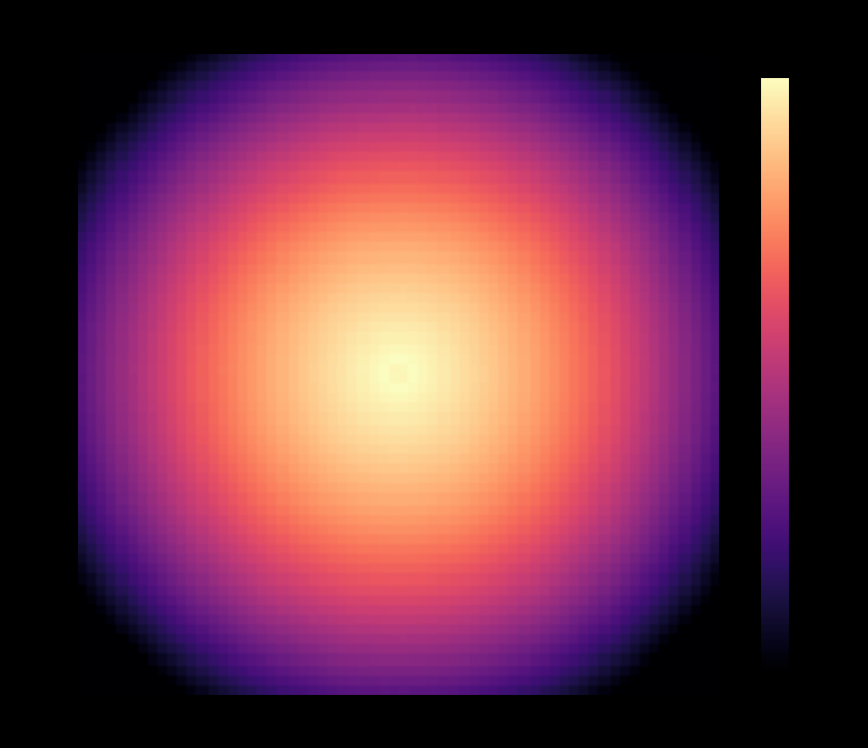

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Use the synthetic image already generated
positive = image[image > 0]

vmin = np.percentile(positive, 5)
vmax = np.max(positive)

plt.figure(figsize=(9, 8), facecolor="black")

plt.imshow(
    image,
    origin="lower",
    extent=[-150, 150, -150, 150],
    cmap="magma",
    norm=LogNorm(vmin=vmin, vmax=vmax),
    interpolation="bilinear"
)

plt.colorbar(
    label="Specific Intensity (CGS)",
    shrink=0.8
)

plt.xlabel("X (AU)")
plt.ylabel("Y (AU)")
plt.title(
    "RADMC-3D | Interstellar Dust Emission\n"
    "100 microns — Logarithmic Scale"
)

plt.tight_layout()
plt.show()